# Rever — Phân tích mẫu tin đăng căn hộ TP.HCM

**Tác giả: Nguyễn Anh Khoa.** Dự án cá nhân từ dữ liệu thu thập trên Rever.vn.

## Tóm tắt
Notebook phân tích dữ liệu giá chào bán: quy mô mẫu, chất lượng dữ liệu, phân bố giá và khác biệt đơn giá/m² giữa các địa bàn. Các số liệu tổng hợp được tính ở các cell bên dưới. Đây là mô tả mẫu tin đã thu thập, không phải định giá giao dịch hay ước lượng đại diện toàn thị trường.

## Bối cảnh và phương pháp
**Câu hỏi:** Trong mẫu này, giá và diện tích phân bố ra sao? Các địa bàn có bao nhiêu tin, trung vị đơn giá/m² thế nào? Diện tích và giá chào có quan hệ gì?

**Grain:** một dòng là một tin đăng, không đảm bảo là một căn hộ duy nhất. Không tự xóa tin hoặc outlier. Giữ tên địa bàn theo nguồn, chưa ánh xạ thay đổi địa giới.

**Định nghĩa:** giá chào = `price_vnd` (VND/tin); đơn giá tính lại = giá chào/diện tích (VND/m²); giá và đơn giá dùng trung vị không trọng số theo tin. Tổng hợp địa bàn kèm `n`; hình so sánh trung vị chỉ hiển thị địa bàn có ít nhất 5 tin hợp lệ. Không cộng giá tin đăng để gọi là doanh thu.

**Giả định và giới hạn:** chưa xác nhận ngày thu thập; ngày đăng có thể thiếu hoặc không chuẩn hóa. Không coi mẫu là chuỗi thời gian. Tin trùng căn hộ, khác biệt dự án, thời điểm và đặc điểm căn hộ có thể ảnh hưởng so sánh.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "rever_apartments_clean_fetcher.csv"
if not DATA.is_file():
    raise FileNotFoundError("Cần CSV nguồn tại data/rever_apartments_clean_fetcher.csv; xem README.")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
df = pd.read_csv(DATA)
required = {"listing_id", "price_vnd", "area_m2", "district"}
assert required <= set(df.columns), f"Thiếu cột: {required - set(df.columns)}"
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
print("SHA256:", hashlib.sha256(DATA.read_bytes()).hexdigest())

Rows: 189 | Columns: 20
SHA256: 1f999db2acffcf710bb97ef1713d72794147579310b5819a9a4b1ad97e925003


## Dữ liệu và kiểm tra chất lượng
Kiểm tra thiếu, trùng dòng, trùng mã tin và kiểu dữ liệu. Bảng không hiển thị tiêu đề/URL/địa chỉ từng tin. Bản portfolio dùng CSV đã làm sạch có sẵn; chưa tái kiểm tra toàn bộ bước scrape và làm sạch từ HTML gốc.

In [2]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str),
                        "missing_n": df.isna().sum(),
                        "missing_pct": df.isna().mean().mul(100).round(1)})
display(quality.sort_values("missing_pct", ascending=False))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Repeated non-null listing IDs:", int(df.loc[df.listing_id.notna(), "listing_id"].duplicated().sum()))
if "listing_date" in df:
    print("Non-null listing_date:", int(df.listing_date.notna().sum()), "/", len(df))

work = df.copy()
for col in ["price_vnd", "area_m2"]:
    work[col] = pd.to_numeric(work[col], errors="coerce")
valid = (np.isfinite(work.price_vnd) & np.isfinite(work.area_m2)
         & work.price_vnd.gt(0) & work.area_m2.gt(0))
print("Valid price/area rows:", int(valid.sum()), "| Invalid rows retained in source:", int((~valid).sum()))
analysis = work.loc[valid].copy()
assert len(analysis) + int((~valid).sum()) == len(df)
assert len(analysis), "Không có tin hợp lệ để tổng hợp"
analysis["district"] = analysis.district.fillna("Unknown")
analysis["asking_price_bn_vnd"] = analysis.price_vnd / 1e9
analysis["unit_price_mn_vnd_m2"] = analysis.price_vnd / analysis.area_m2 / 1e6
if "price_per_m2" in analysis:
    original_unit = pd.to_numeric(analysis.price_per_m2, errors="coerce")
    comparable = original_unit.notna() & np.isfinite(original_unit)
    print("Unit-price rows comparable:", int(comparable.sum()))
    print("Differences >1% vs price/area:", int((~np.isclose(original_unit[comparable],
          analysis.loc[comparable, "unit_price_mn_vnd_m2"] * 1e6, rtol=.01, atol=1)).sum()))

,dtype,missing_n,missing_pct
view_type,float64,189,100.0
floor,float64,189,100.0
discount_pct,float64,189,100.0
old_price_vnd,float64,189,100.0
furnished,float64,189,100.0
listing_date,float64,189,100.0
balcony_direction,str,60,31.7
street,str,1,0.5
project_name,str,0,0.0
listing_url,str,0,0.0


Exact duplicate rows: 0
Repeated non-null listing IDs: 0
Non-null listing_date: 0 / 189
Valid price/area rows: 189 | Invalid rows retained in source: 0
Unit-price rows comparable: 189
Differences >1% vs price/area: 0


Các tin có giá/diện tích thiếu, không hữu hạn hoặc không dương được giữ trong nguồn nhưng không tham gia chỉ số giá. Không impute giá và không cắt outlier. Giá/m² được tính lại để bảo đảm cùng định nghĩa cho mọi quan sát.

## Kết quả — phân bố toàn mẫu
Giá chào tính bằng tỷ VND; đơn giá bằng triệu VND/m². Giữ cả các giá trị lớn trong histogram; dùng trung vị và tứ phân vị để mô tả độ phân tán.

,asking_price_bn_vnd,area_m2,unit_price_mn_vnd_m2
count,189.00,189.00,189.00
mean,13.74,90.28,124.54
std,18.37,39.07,115.72
min,2.30,36.00,40.51
25%,4.40,69.36,62.46
50%,5.30,72.00,70.00
75%,12.95,95.70,150.00
max,88.00,270.00,598.54


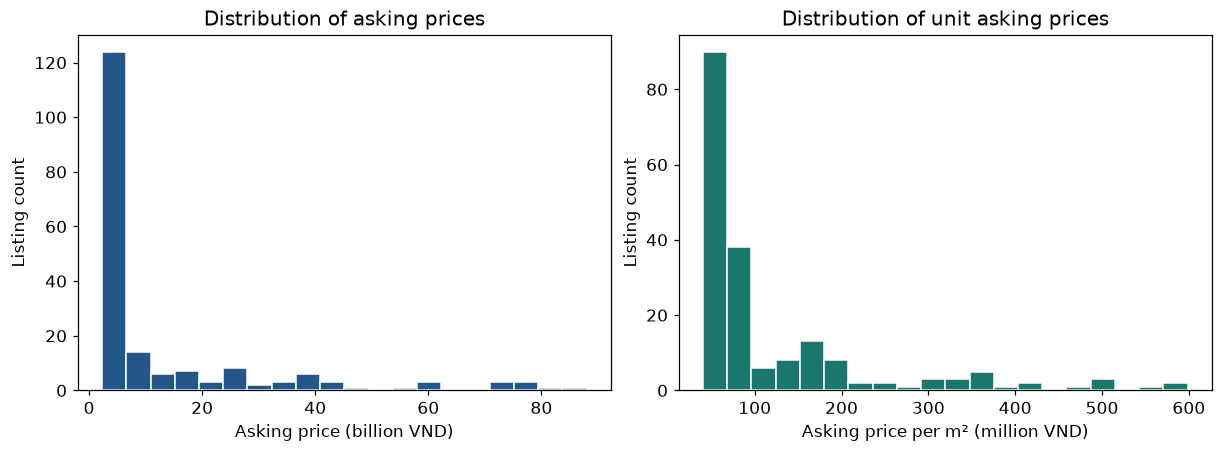

Sample median asking price: 5.30 billion VND.
Median unit asking price: 70.00 million VND/m².


In [3]:
summary = analysis[["asking_price_bn_vnd", "area_m2", "unit_price_mn_vnd_m2"]].describe().round(2)
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].hist(analysis.asking_price_bn_vnd, bins=20, color="#235789", edgecolor="white")
axes[0].set(xlabel="Asking price (billion VND)", ylabel="Listing count", title="Distribution of asking prices")
axes[1].hist(analysis.unit_price_mn_vnd_m2, bins=20, color="#19776e", edgecolor="white")
axes[1].set(xlabel="Asking price per m² (million VND)", ylabel="Listing count", title="Distribution of unit asking prices")
fig.savefig(OUT / "price_distributions.png", bbox_inches="tight")
plt.show()
print(f"Sample median asking price: {analysis.asking_price_bn_vnd.median():.2f} billion VND.")
print(f"Median unit asking price: {analysis.unit_price_mn_vnd_m2.median():.2f} million VND/m².")

## Kết quả — địa bàn và độ phủ
Số tin là độ phủ mẫu, không phải thị phần. So sánh trung vị chưa kiểm soát diện tích, dự án hoặc số phòng. Các địa bàn dưới 5 tin vẫn nằm trong bảng, nhưng không xuất hiện trên biểu đồ trung vị để tránh nhấn mạnh nhóm quá nhỏ.

,listings,median_price_bn,median_area_m2,median_unit_mn,unit_q25,unit_q75
district,,,,,,
Nhà Bè,82,4.50,70.45,63.60,62.46,70.40
Quận 2,56,26.75,114.50,190.19,156.72,342.17
Quận 7,35,3.90,69.19,57.33,54.37,70.36
Bình Thạnh,6,14.35,89.50,158.80,145.75,168.98
Quận 9,5,3.40,69.00,57.14,55.00,63.89
Bình Chánh,2,3.17,72.00,43.49,42.00,44.98
Quận 4,2,10.90,90.00,118.67,111.33,126.00
Quận 1,1,72.00,121.83,590.99,590.99,590.99


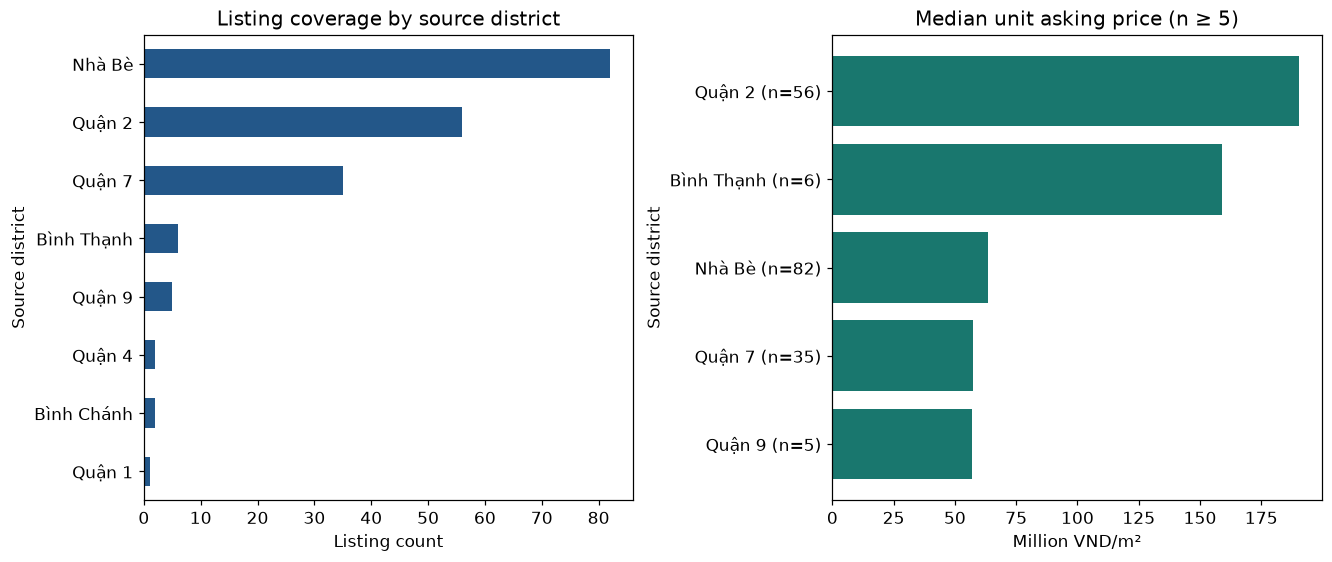

In [4]:
districts = analysis.groupby("district", dropna=False).agg(
    listings=("price_vnd", "size"),
    median_price_bn=("asking_price_bn_vnd", "median"),
    median_area_m2=("area_m2", "median"),
    median_unit_mn=("unit_price_mn_vnd_m2", "median"),
    unit_q25=("unit_price_mn_vnd_m2", lambda x: x.quantile(.25)),
    unit_q75=("unit_price_mn_vnd_m2", lambda x: x.quantile(.75)))
assert districts.listings.sum() == len(analysis)
display(districts.sort_values("listings", ascending=False).round(2))
districts.to_csv(OUT / "district_summary.csv", encoding="utf-8-sig")
eligible = districts.loc[districts.listings.ge(5)].sort_values("median_unit_mn")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
districts.listings.sort_values().plot.barh(ax=axes[0], color="#235789")
axes[0].set(title="Listing coverage by source district", xlabel="Listing count", ylabel="Source district")
if len(eligible):
    labels = [f"{name} (n={int(row.listings)})" for name, row in eligible.iterrows()]
    axes[1].barh(labels, eligible.median_unit_mn, color="#19776e")
axes[1].set(title="Median unit asking price (n ≥ 5)", xlabel="Million VND/m²", ylabel="Source district")
fig.savefig(OUT / "district_comparison.png", bbox_inches="tight")
plt.show()

## Kết quả — diện tích và giá chào
Mỗi điểm là một tin. Hệ số tương quan Spearman mô tả quan hệ thứ hạng, không có ý nghĩa nhân quả và không phải độ chính xác mô hình dự báo.

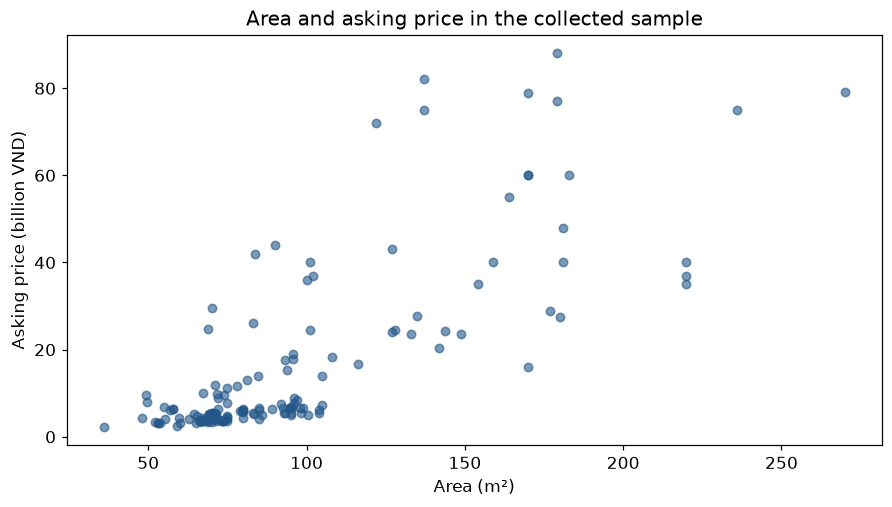

Spearman correlation (area, asking price): 0.755


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.scatter(analysis.area_m2, analysis.asking_price_bn_vnd, alpha=.6, s=30, color="#235789")
ax.set(xlabel="Area (m²)", ylabel="Asking price (billion VND)", title="Area and asking price in the collected sample")
fig.savefig(OUT / "area_vs_price.png", bbox_inches="tight")
plt.show()
rho = analysis[["area_m2", "asking_price_bn_vnd"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation (area, asking price): {rho:.3f}")

## Kết luận và hành động tiếp theo
Cell dưới đây tạo tóm tắt từ dữ liệu vừa tính, tránh chép số từ tài liệu cũ. Không kết luận khu vực nào là cơ hội đầu tư chỉ dựa vào mẫu tin đăng.

In [6]:
notes = [
    f"Sample: {len(df)} listings; {len(analysis)} valid for price/area analysis.",
    f"Median asking price: {analysis.asking_price_bn_vnd.median():.2f} billion VND.",
    f"Median unit asking price: {analysis.unit_price_mn_vnd_m2.median():.2f} million VND/m².",
    f"Area/asking-price Spearman correlation: {rho:.3f}.",
    "District comparisons are descriptive, not controlled like-for-like valuations.",
    "Collection date is unconfirmed; findings describe this saved sample only.",
]
print("\n".join(notes))
(OUT / "findings.txt").write_text("\n".join(notes) + "\n", encoding="utf-8")

Sample: 189 listings; 189 valid for price/area analysis.
Median asking price: 5.30 billion VND.
Median unit asking price: 70.00 million VND/m².
Area/asking-price Spearman correlation: 0.755.
District comparisons are descriptive, not controlled like-for-like valuations.
Collection date is unconfirmed; findings describe this saved sample only.


344

**Khuyến nghị:** dùng bảng độ phủ để lập kế hoạch thu thập bổ sung; kiểm tra khả năng cùng một căn xuất hiện nhiều tin; thu thập thời điểm và thuộc tính dự án trước khi so sánh căn tương đồng. Nếu mục tiêu là dự báo, cần thiết kế kiểm định theo thời gian/dự án và phân biệt giá chào với giá giao dịch.

**Phần mở rộng ML:** notebook `Rever_Price_Segment_Classification_Port.ipynb` được sao chép từ dự án hiện có, giữ nguyên output lịch sử; không được chạy lại trong lần chuẩn bị EDA này. Các kết quả mô hình không phải kết quả của notebook mô tả hiện tại.

**Đóng góp:** bản học phần do tác giả thực hiện và dùng AI hỗ trợ tối ưu; notebook DA này được tái cấu trúc với AI. Tác giả cần đọc, chạy và giải thích kết quả trước phỏng vấn.